This notebook shows how to use python scripts to extract data points from a model with an arbitrary grid at the locations and times of the sea ice thickness CDR https://psc.apl.uw.edu/sea_ice_cdr/ and compare them.

Steps:
1. Extract model ice thickness and snow depth at all CDR observations (one step, ~1-2 min per model run).
2. Read the extracted data, compute thickness/draft for all observations (`toThick`), and compare by source, region and season.

In [1]:
import logging
import os
import sys

sys.path.append("/home/axel/ax_python_lib/im")
sys.path.append("/home/axel/ax_python_lib/thickCDR/")
sys.path.append("/home/axel/ax_python_lib/axel_utilities")
import axutil
# various utilities for model data manipulation
import ax_im_utils as im

# load routines from the match_thickCDR_model library
from match_thickCDR_model import *

%load_ext autoreload
%autoreload 2

import pandas as pd
pd.set_option('display.float_format','{:.2f}'.format)
logging.basicConfig(stream=sys.stdout, level=logging.INFO)

ERROR 1: PROJ: proj_create_from_database: Open of /home/axel/miniforge3/envs/pangeo312_m2/share/proj failed


## Choose the model run

Model runs are defined in `RUNS` in `match_thickCDR_model.py`: grid, model directory, file variables (`['hiday','snowday']` daily or `['heff','snow']` monthly) and the maximum distance [km] between an observation and the closest model grid cell.

In [2]:
model_id = "2sstC"  # current public PIOMAS run
run = RUNS[model_id]
gridName = run["gridName"]
run

{'model': 'PIOMAS',
 'gridName': '360X120',
 'model_group': '360X120',
 'dist_thresh': 25.0,
 'nt': 47,
 'file_varnames': ['hiday', 'snowday']}

A run that isn't in `RUNS` yet can be added here (or better, in `match_thickCDR_model.py` so it's kept). The model path defaults to `/data/axel0/model_results/<model_group>/<model_id>/nc/`, or set `model_path`:

```python
RUNS["myrun"] = dict(gridName="360X120", model_group="", dist_thresh=25.0, nt=46,
                     file_varnames=["hiday", "snowday"], model_path="/data/axel0/model_results/myrun/nc/")
```

## Extract model data at the CDR observations

Writes `extractDir/<gridName>/<model_id>/<model_id>.extract.<var0>.<var1>.nc` with all sources. Set `extract = True` to (re)run it; it's only needed once per model run (or when the CDR file changes). The same thing from the command line: `python match_thickCDR_model.py <model_id>`.

Observations are matched to the closest grid cell that has model data (within `dist_thresh`) and the closest model time (within 15 days; monthly fields are centered on mid-month).

In [3]:
extract = False
cdr_file = "/home/axel/projects/sea_ice_cdr/idl/axel_cdr/ncdf_dir/uThickCDR_summaries.20251010_V1.0.nc"
if extract:
    driver_onepass(model_id, cdr_file=cdr_file)

## Read the extracted data and compute thickness and draft

The CDR contains draft, thickness and ice+snow thickness, depending on source. `toThick` fills in the others using the model snow depth, and removes the 0.29 m submarine draft bias. It returns a new data set and is safe to call twice.

In [4]:
obsAndModel = readMerged(model_id, gridName)  # all sources; sources=[...] to select
obsAndModel.load()
obsAndModel = toThick(obsAndModel)
print(obsAndModel.sizes["cdr_index"], "matched observations")

Reading data from  /home/axel/ax_python_lib/thickCDR/extractDir/
INFO:root:Reading one-pass extraction /home/axel/ax_python_lib/thickCDR/extractDir/360X120/2sstC/2sstC.extract.hiday.snowday.nc


INFO:httpx:HTTP Request: GET https://raw.githubusercontent.com/IrishMarineInstitute/awesome-erddap/master/erddaps.json "HTTP/1.1 200 OK"


1919
INFO:root:Removing Submarine Bias


before bias removal: : 2.8513913
After bias removal: : 2.5613914
427791
INFO:root:Number of missing Draft values : 24966


INFO:root:Number of missing THICK values : 24966


INFO:root:Number of missing THICK_ICE_SNOW values : 24966



Coordinates of Missing Values:
cdr_index: [ 2520000  2520005  2520006 ... 21025034 21025035 21025036]
454152 matched observations


## Statistics by source

CryoSat-AWI is ~90% of all matched observations, so the `ALL` row is dominated by it.

In [5]:
source_stats(obsAndModel)

,n,obs_mean,mod_mean,bias(mod-obs),rmse,r
AIR-EM,1395,2.25,1.98,-0.27,0.95,0.61
AWI-GS,134,1.10,0.80,-0.30,0.80,0.50
BGEP,693,1.34,1.55,0.21,0.42,0.89
BIO_LS,36,0.92,1.33,0.41,0.81,0.45
CanCoast,1361,1.28,1.99,0.71,1.21,0.35
CryoSat-AWI,391416,1.29,1.45,0.16,0.51,0.79
Davis_St,67,0.75,0.43,-0.32,0.63,0.75
ICESAT1-G,29244,1.91,2.02,0.11,0.87,0.52
IOS-CHK,26,1.28,1.50,0.23,0.38,0.94
IOS-EBS,382,1.40,1.46,0.06,0.79,0.66


Draft comparison (model draft computed from model thickness and snow):

In [6]:
source_stats(obsAndModel, draft=True)

,n,obs_mean,mod_mean,bias(mod-obs),rmse,r
AIR-EM,1395,2.43,2.19,-0.24,0.86,0.78
AWI-GS,134,1.03,1.08,0.05,0.93,0.51
BGEP,693,1.24,1.72,0.48,0.69,0.86
BIO_LS,36,0.88,1.65,0.77,1.09,0.50
CanCoast,1361,1.98,2.63,0.64,1.09,0.81
CryoSat-AWI,391416,1.59,1.74,0.15,0.46,0.87
Davis_St,67,0.69,0.53,-0.17,0.55,0.67
ICESAT1-G,29244,2.33,2.43,0.10,0.79,0.67
IOS-CHK,26,1.20,1.76,0.57,0.67,0.92
IOS-EBS,382,1.29,1.57,0.28,0.88,0.65


## Compare several model runs

Bias (model - observation) by source for runs that have been extracted, labeled by model (PIOMAS, CAPMAS, GIOMAS) and run.

In [7]:
runs = ["2sstC", "1c", "2c", "2cfs"]  # 2sstC = public PIOMAS
data = {}  # extracted + toThick data for each run, reused below
for mid in runs:
    ds = readMerged(mid, RUNS[mid]["gridName"])
    ds.load()
    data[mid] = toThick(ds)
label = {mid: RUNS[mid]["model"] + " " + mid for mid in runs}  # e.g. "PIOMAS 2sstC"
pd.concat({label[mid]: source_stats(data[mid])[["n", "bias(mod-obs)", "rmse", "r"]] for mid in runs}, axis=1)

Reading data from  /home/axel/ax_python_lib/thickCDR/extractDir/
INFO:root:Reading one-pass extraction /home/axel/ax_python_lib/thickCDR/extractDir/360X120/2sstC/2sstC.extract.hiday.snowday.nc


1919
INFO:root:Removing Submarine Bias


before bias removal: : 2.8513913
After bias removal: : 2.5613914
427791
INFO:root:Number of missing Draft values : 24966


INFO:root:Number of missing THICK values : 24966


INFO:root:Number of missing THICK_ICE_SNOW values : 24966



Coordinates of Missing Values:
cdr_index: [ 2520000  2520005  2520006 ... 21025034 21025035 21025036]
Reading data from  /home/axel/ax_python_lib/thickCDR/extractDir/
INFO:root:Reading one-pass extraction /home/axel/ax_python_lib/thickCDR/extractDir/912X672/1c/1c.extract.heff.snow.nc


... (12 outputs left out)

INFO:root:Number of missing THICK values : 25071


INFO:root:Number of missing THICK_ICE_SNOW values : 25071



Coordinates of Missing Values:
cdr_index: [ 2520000  2520005  2520006 ... 21025034 21025035 21025036]


PIOMAS 2sstC                         CAPMAS 1c                \
                        n bias(mod-obs) rmse    r         n bias(mod-obs)   
AIR-EM               1395         -0.27 0.95 0.61      1229          1.07   
AWI-GS                134         -0.30 0.80 0.50       134          0.90   
BGEP                  693          0.21 0.42 0.89       693          0.73   
BIO_LS                 36          0.41 0.81 0.45        36          0.57   
CanCoast             1361          0.71 1.21 0.35       776          1.06   
CryoSat-AWI        391416          0.16 0.51 0.79    381652          0.88   
Davis_St               67         -0.32 0.63 0.75        67          0.10   
ICESAT1-G           29244          0.11 0.87 0.52     29220          0.93   
IOS-CHK                26          0.23 0.38 0.94        26          0.62   
IOS-EBS               382          0.06 0.79 0.66       382          0.23   
IceBridge-QL         1517         -0.21 0.78 0.68      1517          0.80   
IceBridge-V2          932         -0.33 0.96 0.42       933          0.90   
NPEO                   64         -1.01 1.27 0.52        64          0.02   
UKSUB-AN              149         -0.36 1.54 0.61       149          1.02   
USSUB-AN              646         -0.36 0.79 0.80       646         -0.06   
USSUB-DG             1124         -0.08 0.74 0.71      1122          0.02   
ALL                429186          0.16 0.56 0.77    418646          0.88   

                       CAPMAS 2c                         GIOMAS 2cfs  \
             rmse    r         n bias(mod-obs) rmse    r           n   
AIR-EM       1.51 0.67   1224.00          0.22 0.96 0.70        1395   
AWI-GS       1.17 0.49       NaN           NaN  NaN  NaN         134   
BGEP         0.86 0.82    693.00          0.31 0.57 0.82         693   
BIO_LS       1.02 0.29     36.00          0.01 0.57 0.69          36   
CanCoast     1.50 0.25    125.00          1.92 2.33 0.27        1522   
CryoSat-AWI  1.14 0.73 381652.00          0.51 0.76 0.76      402251   
Davis_St     0.52 0.75     67.00          0.01 0.52 0.75          67   
ICESAT1-G    1.31 0.63  29220.00          0.39 0.98 0.55       29393   
IOS-CHK      0.70 0.94     26.00          0.26 0.40 0.96          26   
IOS-EBS      1.02 0.56      9.00         -0.47 1.04 0.34         382   
IceBridge-QL 1.11 0.74   1517.00          0.23 0.77 0.73        1518   
IceBridge-V2 1.42 0.55    933.00          0.25 0.95 0.57         933   
NPEO         0.91 0.22     43.00         -0.62 1.12 0.43          64   
UKSUB-AN     1.88 0.59       NaN           NaN  NaN  NaN         149   
USSUB-AN     0.72 0.77     58.00         -0.14 0.56 0.85         646   
USSUB-DG     0.83 0.66    121.00          0.49 0.63 0.55        1124   
ALL          1.15 0.73 415724.00          0.50 0.78 0.75      440333   

                                      
             bias(mod-obs) rmse    r  
AIR-EM               -0.10 0.91 0.63  
AWI-GS               -0.49 0.74 0.59  
BGEP                  0.64 0.74 0.87  
BIO_LS                0.36 0.70 0.68  
CanCoast              0.71 1.81 0.16  
CryoSat-AWI           0.44 0.70 0.74  
Davis_St             -0.12 0.50 0.78  
ICESAT1-G             0.17 0.95 0.36  
IOS-CHK               0.50 0.62 0.92  
IOS-EBS               0.07 0.78 0.65  
IceBridge-QL         -0.09 0.82 0.60  
IceBridge-V2         -0.17 0.89 0.46  
NPEO                 -1.00 1.31 0.32  
UKSUB-AN             -1.09 1.85 0.69  
USSUB-AN             -0.54 1.01 0.67  
USSUB-DG             -0.40 0.97 0.52  
ALL                   0.42 0.73 0.71

## AIR-EM only: all runs

Airborne EM (AIR-EM) measures total (ice + snow) thickness. Two comparisons:
- **ice + snow**: observed `THICK_ICE_SNOW` vs model `sit + sisnthick`. No snow assumption needed.
- **ice**: observed ice thickness (`THICK_ICE_SNOW` minus model snow, from `toThick`) vs model `sit`.

Only AIR-EM observations matched in all runs are used, so every run is compared against the same points (CAPMAS 2c starts in 2003, CAPMAS has fewer coastal cells).

In [8]:
airem = {mid: d.isel(cdr_index=(d.SOURCE == "AIR-EM").values) for mid, d in data.items()}
common = sorted(set.intersection(*[set(a.cdr_index.values) for a in airem.values()]))
airem = {mid: a.sel(cdr_index=common) for mid, a in airem.items()}
print(len(common), "AIR-EM observations in all runs (of", {mid: int((d.SOURCE == "AIR-EM").sum()) for mid, d in data.items()}, ")")

cols = ["n", "obs_mean", "mod_mean", "bias(mod-obs)", "rmse", "r"]
table = pd.concat({
    "ice + snow": pd.DataFrame({label[mid]: source_stats(a, ice_snow=True).loc["ALL", cols] for mid, a in airem.items()}).T,
    "ice": pd.DataFrame({label[mid]: source_stats(a).loc["ALL", cols] for mid, a in airem.items()}).T,
}, axis=1)
table

1224 AIR-EM observations in all runs (of {'2sstC': 1395, '1c': 1229, '2c': 1224, '2cfs': 1395} )


ice + snow                                               ice  \
                      n obs_mean mod_mean bias(mod-obs) rmse    r       n   
PIOMAS 2sstC    1224.00     2.44     2.22         -0.23 0.95 0.66 1224.00   
CAPMAS 1c       1224.00     2.44     3.52          1.07 1.51 0.70 1224.00   
CAPMAS 2c       1224.00     2.44     2.67          0.22 0.96 0.73 1224.00   
GIOMAS 2cfs     1224.00     2.44     2.40         -0.05 0.91 0.67 1224.00   

                                                        
             obs_mean mod_mean bias(mod-obs) rmse    r  
PIOMAS 2sstC     2.29     2.06         -0.23 0.95 0.59  
CAPMAS 1c        2.28     3.36          1.07 1.51 0.67  
CAPMAS 2c        2.30     2.53          0.22 0.96 0.70  
GIOMAS 2cfs      2.26     2.22         -0.05 0.91 0.62

By season: AIR-EM campaigns are in spring (March-May, mostly thicker multiyear ice north of Greenland/Canada and the Lincoln Sea) and summer (June-October, e.g. Polarstern and IceBird summer flights).

In [9]:
def season(ds):
    m = ds.obs_time.dt.month.values
    return np.where((m >= 3) & (m <= 5), "spring (Mar-May)", "summer (Jun-Oct)")

rows = {}
for mid, a in airem.items():
    for s in ["spring (Mar-May)", "summer (Jun-Oct)"]:
        sub = a.isel(cdr_index=season(a) == s)
        rows[(s, label[mid])] = source_stats(sub, ice_snow=True).loc["ALL", cols]
pd.DataFrame(rows).T

,,n,obs_mean,mod_mean,bias(mod-obs),rmse,r
spring (Mar-May),PIOMAS 2sstC,637.00,2.90,2.80,-0.10,1.07,0.59
summer (Jun-Oct),PIOMAS 2sstC,587.00,1.95,1.58,-0.36,0.81,0.50
spring (Mar-May),CAPMAS 1c,637.00,2.90,3.90,1.00,1.52,0.68
summer (Jun-Oct),CAPMAS 1c,587.00,1.95,3.09,1.15,1.50,0.65
spring (Mar-May),CAPMAS 2c,637.00,2.90,3.28,0.38,1.06,0.70
summer (Jun-Oct),CAPMAS 2c,587.00,1.95,2.00,0.05,0.84,0.64
spring (Mar-May),GIOMAS 2cfs,637.00,2.90,3.02,0.11,1.03,0.62
summer (Jun-Oct),GIOMAS 2cfs,587.00,1.95,1.73,-0.22,0.76,0.43


By campaign (ice + snow bias, model - observation, m). Campaign = `PLATFORM` in the CDR.

In [10]:
bias = {}
for mid, a in airem.items():
    df = pd.DataFrame({"campaign": a.PLATFORM.values,
                       "diff": a.sit.values + a.sisnthick.values - a.THICK_ICE_SNOW[:, 0].values,
                       "obs": a.THICK_ICE_SNOW[:, 0].values})
    g = df.groupby("campaign")
    bias[label[mid]] = g["diff"].mean()
by_campaign = pd.DataFrame(bias)
by_campaign.insert(0, "obs_mean", g["obs"].mean())
by_campaign.insert(0, "n", g.size())
by_campaign

,n,obs_mean,PIOMAS 2sstC,CAPMAS 1c,CAPMAS 2c,GIOMAS 2cfs
campaign,,,,,,
2004ARK19,28,1.68,0.14,1.20,0.79,-0.10
2004ARK20,11,2.57,-0.76,1.02,-1.22,-1.14
2004GRNICE,18,4.45,-0.05,0.52,-0.55,-1.09
2005GRNICE,16,3.88,-1.03,1.87,0.69,-0.01
2006CRYVEX,18,4.83,-1.60,0.34,-0.47,-1.71
2007ARK22,30,1.26,-0.01,1.00,-0.26,0.22
2007POLAIR,9,3.29,-0.04,0.93,0.21,-0.00
2007SEDNA,44,2.53,0.02,0.65,0.08,0.38
2007SIZONET,5,2.80,-0.14,0.92,-0.21,0.39


Scatter plots, ice thickness (`scatter_plot` compares `THICK` with `sit`):

Model has Nan:  False
Observations have Nan: False
[0.95050838 0.4854189 ]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.348
Model:                            OLS   Adj. R-squared:                  0.348
Method:                 Least Squares   F-statistic:                     653.6
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          7.89e-116
Time:                        12:33:28   Log-Likelihood:                -1353.9
No. Observations:                1224   AIC:                             2712.
Df Residuals:                    1222   BIC:                             2722.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

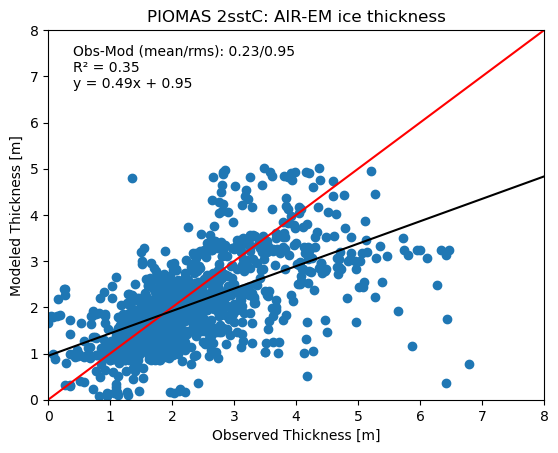

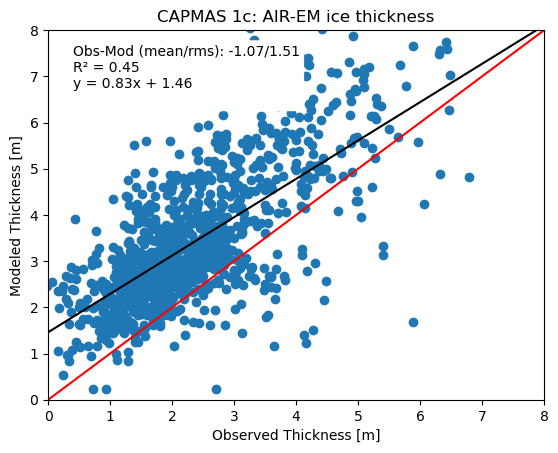

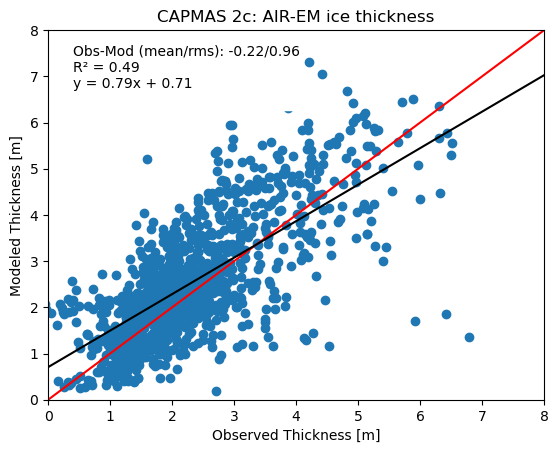

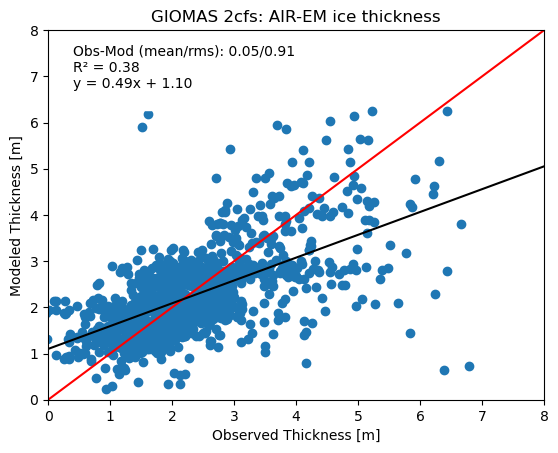

In [11]:
for mid, a in airem.items():
    fig, ax, results = scatter_plot(a, mid, title=label[mid] + ": AIR-EM ice thickness", max_thick=8.)

## Scatter plot and histograms for observed and modeled ice thickness

Model has Nan:  False
Observations have Nan: False
[0.44382238 0.78299092]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.621
Model:                            OLS   Adj. R-squared:                  0.621
Method:                 Least Squares   F-statistic:                 6.420e+05
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:33:30   Log-Likelihood:            -2.5018e+05
No. Observations:              391416   AIC:                         5.004e+05
Df Residuals:                  391414   BIC:                         5.004e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

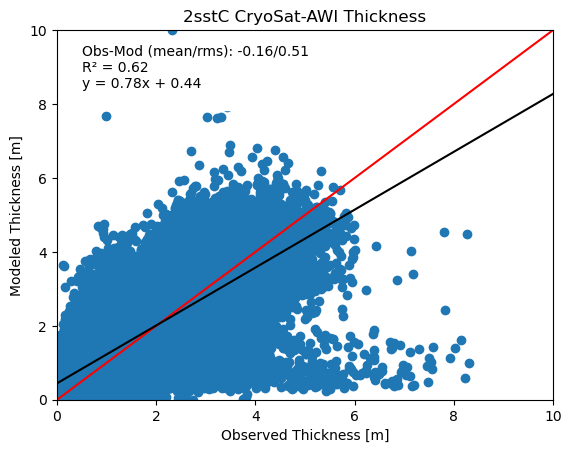

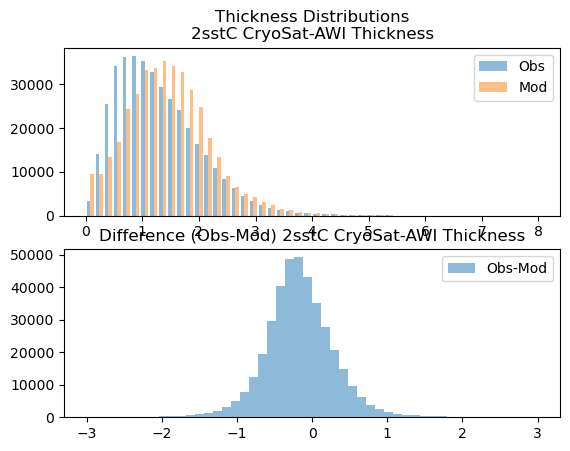

In [12]:
select_sources = ["CryoSat-AWI"]
sub = obsAndModel.isel(cdr_index=obsAndModel.SOURCE.isin(select_sources).values)
title = model_id + " " + ":".join(select_sources) + " Thickness"
fig, ax, results = scatter_plot(sub, model_id, title=title, draft=False)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

## Same for draft

Model has Nan:  False
Observations have Nan: False
[0.22600686 1.20207313]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.735
Method:                 Least Squares   F-statistic:                     1922.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          8.75e-202
Time:                        12:33:31   Log-Likelihood:                -482.23
No. Observations:                 693   AIC:                             968.5
Df Residuals:                     691   BIC:                             977.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

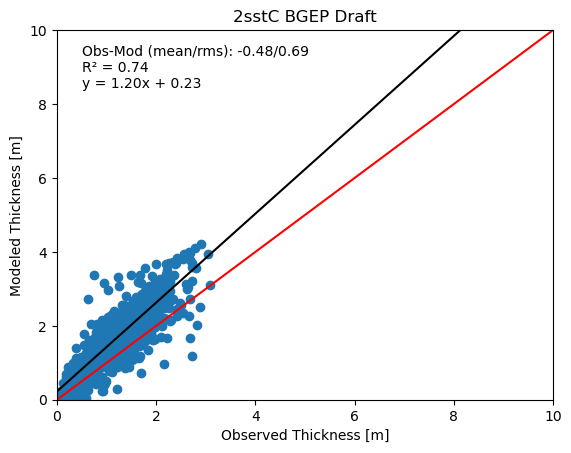

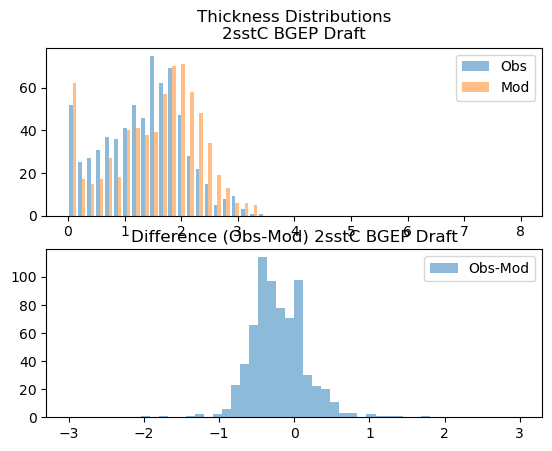

In [13]:
select_sources = ["BGEP"]
sub = obsAndModel.isel(cdr_index=obsAndModel.SOURCE.isin(select_sources).values)
title = model_id + " " + ":".join(select_sources) + " Draft"
fig, ax, results = scatter_plot(sub, model_id, title=title, draft=True)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

## Demonstrate how subsetting by space can be done

In [14]:
import geopandas as gpd
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature 
from shapely.geometry import Point,MultiPoint,Polygon, mapping
from model_maps_arctic import map_arctic_ortho,map_arctic_region,arctic_map_outline,ax_reset_norm

Remove the satellite sources (they dominate by number) and keep the mean values (`Mean Max Min Sigma` = 0), which is necessary for creating the pandas data frame.

In [15]:
satellite = ["CryoSat-AWI", "ENVISAT", "ICESAT1-G"]
insitu = obsAndModel.isel(cdr_index=~obsAndModel.SOURCE.isin(satellite).values)
sub = insitu.isel({"Mean Max Min Sigma": 0})
sub["lon"] = axutil.lonTo180(sub.lon)  # appears necessary otherwise doesn't work.
df = sub.to_dataframe()
geometry = gpd.points_from_xy(df["lon"], df["lat"])

## Create a geopanda data frame from the geometry data created above

In [16]:
gdf_points = gpd.GeoDataFrame(df,geometry=geometry, crs="EPSG:4326")

## Now define a Polygon in Lon,lat Space and create a geopanda polygon 

In [17]:
polygon = Polygon([(-100, 70), (-100, 82), (-180, 82), (-180, 70)])
gdf_polygon = gpd.GeoDataFrame(geometry=[polygon], crs="EPSG:4326")

## Check if the list of points (cdr observations) is inside the polygon defined above

In [18]:
points_within_polygon = gpd.sjoin(gdf_points, gdf_polygon, predicate='within')

## For checking that the subsetting works, plot the area that is selected

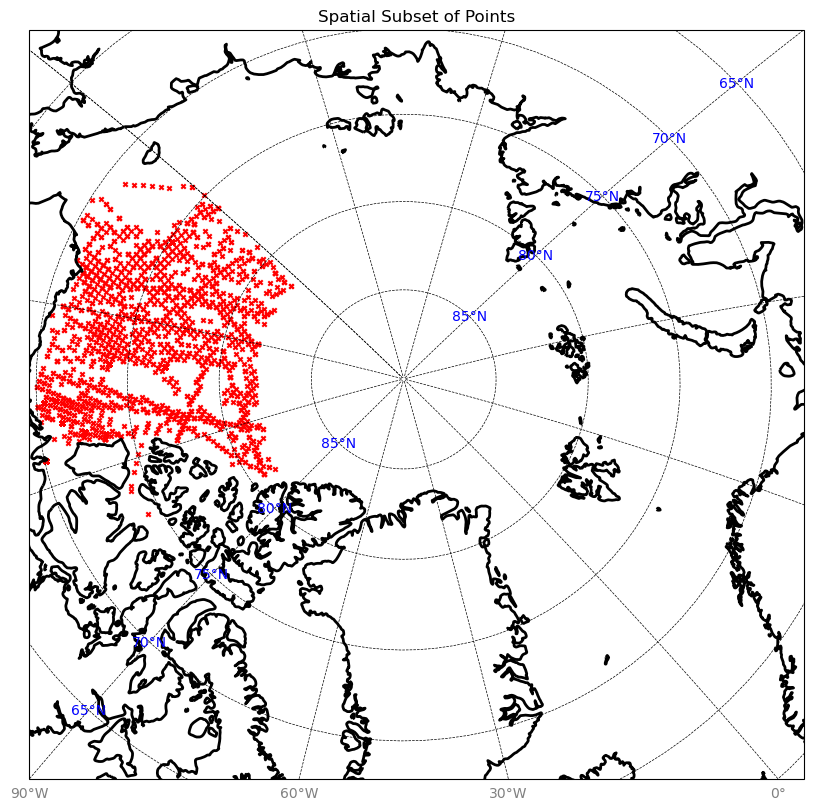

In [19]:
ax,fig,gl=arctic_map_outline("Spatial Subset of Points",land_fill=False)
plons=points_within_polygon['geometry'].x
plats=points_within_polygon['geometry'].y
ax.scatter(x=plons,y=plats,s=10,marker='x',color='red',transform=ccrs.PlateCarree())
plt.show()

## Now create the scatter plot and histogram of the subset

Model has Nan:  False
Observations have Nan: False
[0.81016081 0.62359915]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.561
Model:                            OLS   Adj. R-squared:                  0.561
Method:                 Least Squares   F-statistic:                     4109.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:33:34   Log-Likelihood:                -2529.4
No. Observations:                3212   AIC:                             5063.
Df Residuals:                    3210   BIC:                             5075.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

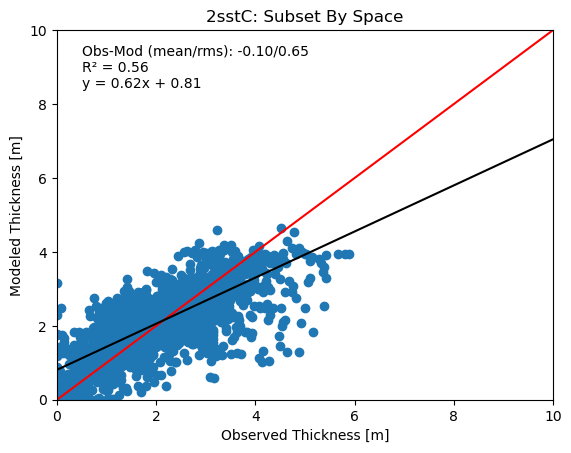

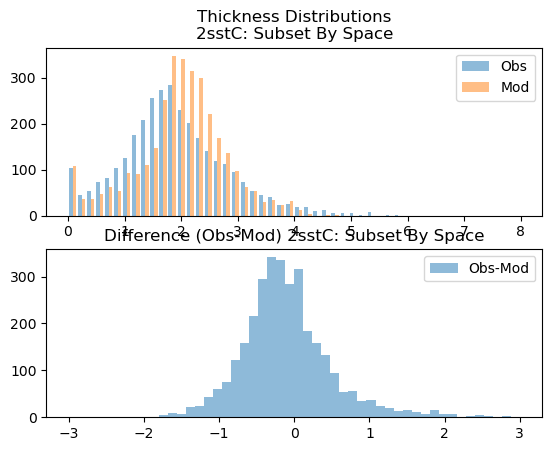

In [20]:
title = model_id + ": Subset By Space"
cdr_index = points_within_polygon.index
sub = insitu.sel(cdr_index=cdr_index)
fig, ax, results = scatter_plot(sub, model_id, title=title)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

## Winter and summer

Model has Nan:  False
Observations have Nan: False
[1.3279931  0.43427489]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.394
Model:                            OLS   Adj. R-squared:                  0.393
Method:                 Least Squares   F-statistic:                     1307.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          4.99e-221
Time:                        12:33:35   Log-Likelihood:                -1324.4
No. Observations:                2015   AIC:                             2653.
Df Residuals:                    2013   BIC:                             2664.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

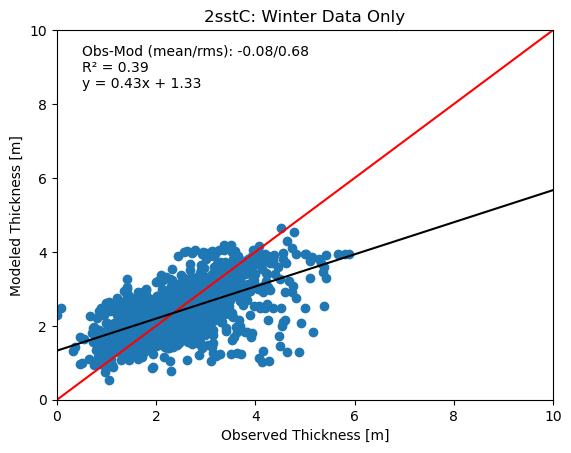

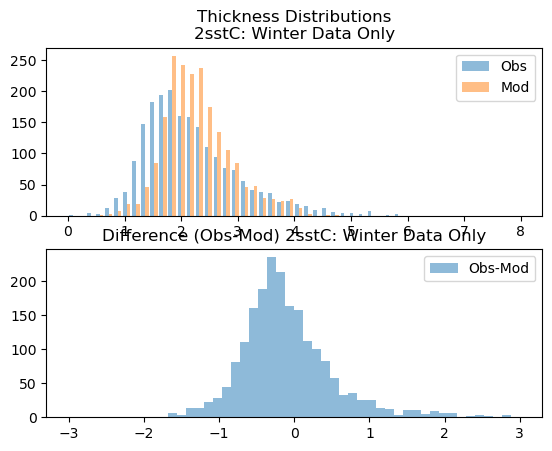

In [21]:
def is_winter(month):
    return (month >= 1) & (month <= 4)

sub = insitu.sel(cdr_index=cdr_index)
sub = sub.isel(cdr_index=is_winter(sub["obs_time.month"]))
title = model_id + ": Winter Data Only"
fig, ax, results = scatter_plot(sub, model_id, title=title)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

Model has Nan:  False
Observations have Nan: False
[0.45720031 0.75344193]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.620
Model:                            OLS   Adj. R-squared:                  0.619
Method:                 Least Squares   F-statistic:                     1778.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          2.05e-231
Time:                        12:33:35   Log-Likelihood:                -895.25
No. Observations:                1094   AIC:                             1795.
Df Residuals:                    1092   BIC:                             1805.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

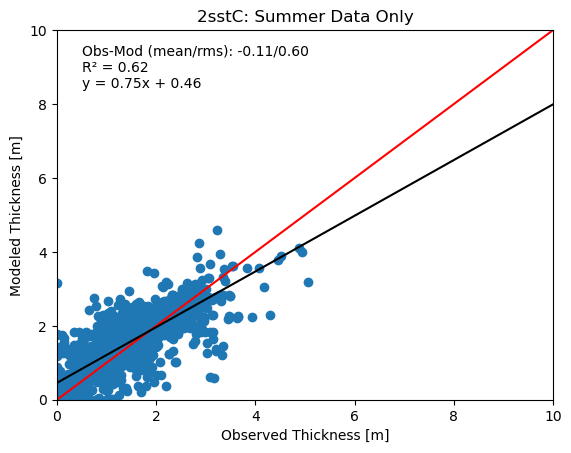

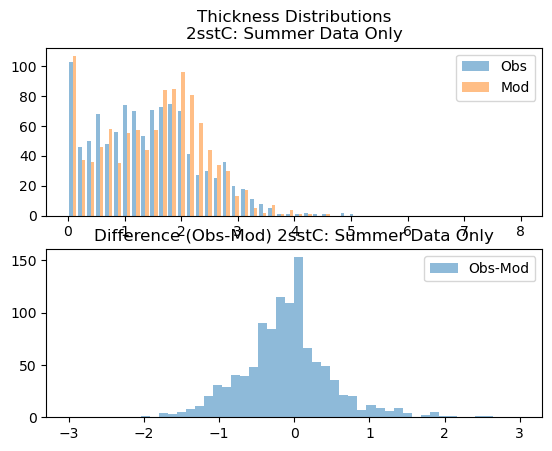

In [22]:
def is_summer(month):
    return (month >= 5) & (month <= 11)

sub = insitu.sel(cdr_index=cdr_index)
sub = sub.isel(cdr_index=is_summer(sub["obs_time.month"]))
title = model_id + ": Summer Data Only"
fig, ax, results = scatter_plot(sub, model_id, title=title)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

Statistics by source for the summer subset:

In [23]:
source_stats(sub)

,n,obs_mean,mod_mean,bias(mod-obs),rmse,r
AIR-EM,1,5.06,3.17,-1.89,1.89,NaN
BGEP,410,1.15,1.26,0.11,0.41,0.88
CanCoast,47,1.27,1.17,-0.10,0.41,0.82
IOS-CHK,16,0.96,1.25,0.28,0.41,0.95
IOS-EBS,228,1.26,1.16,-0.10,0.77,0.71
USSUB-AN,184,1.78,2.04,0.26,0.66,0.79
USSUB-DG,208,1.76,2.03,0.27,0.69,0.71
ALL,1094,1.40,1.51,0.11,0.60,0.79
